In [3]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the car dataset

df = pd.read_csv("CAR DETAILS FROM CAR DEKHO.csv")

# Display first 5 rows

df.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner


In [4]:
# Check the number of rows and columns
print("Dataset Shape:", df.shape)

# Display column names
print("\nColumn Names:")
print(df.columns)

# Check data types
print("\nDataset Information:")
df.info()

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check duplicate rows
print("\nDuplicate Rows:", df.duplicated().sum())

Dataset Shape: (4340, 8)

Column Names:
Index(['name', 'year', 'selling_price', 'km_driven', 'fuel', 'seller_type',
       'transmission', 'owner'],
      dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4340 entries, 0 to 4339
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   name           4340 non-null   object
 1   year           4340 non-null   int64 
 2   selling_price  4340 non-null   int64 
 3   km_driven      4340 non-null   int64 
 4   fuel           4340 non-null   object
 5   seller_type    4340 non-null   object
 6   transmission   4340 non-null   object
 7   owner          4340 non-null   object
dtypes: int64(3), object(5)
memory usage: 271.4+ KB

Missing Values:
name             0
year             0
selling_price    0
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
dtype: int64

Duplicate Rows: 763


                   Feature  Importance
9      transmission_Manual    0.244025
1                km_driven    0.127027
2                  car_age    0.121760
0                     year    0.113241
3              fuel_Diesel    0.070997
14              brand_Audi    0.052723
6              fuel_Petrol    0.042618
28              brand_Land    0.040374
39            brand_Toyota    0.037311
7   seller_type_Individual    0.018456
15               brand_BMW    0.013794
32     brand_Mercedes-Benz    0.010424
31            brand_Maruti    0.010327
25            brand_Jaguar    0.010163
30          brand_Mahindra    0.009194


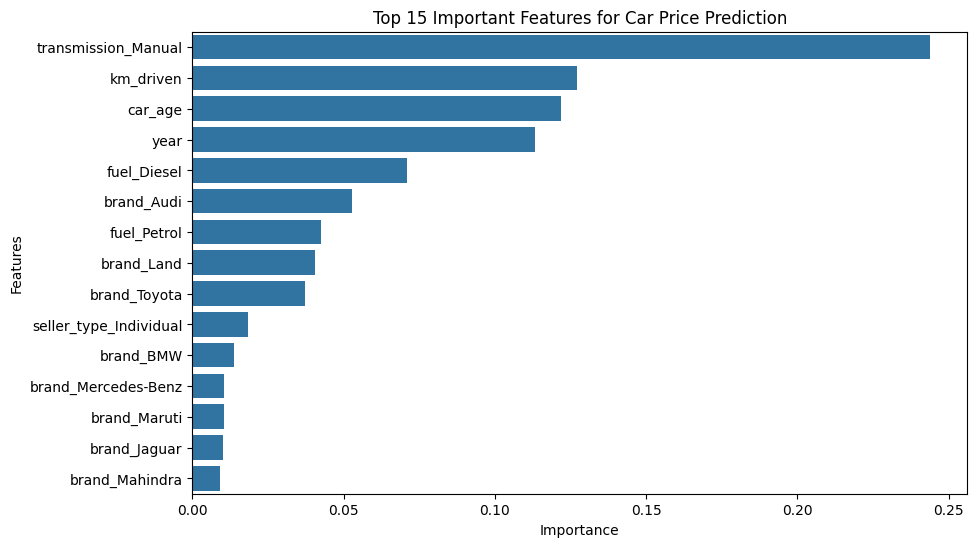

In [ ]:
# Get feature importance from Random Forest
importance = rf_model.feature_importances_

# Create DataFrame
feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': importance
})

# Sort by importance
feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

# Display top 15 features
print(feature_importance.head(15))

# Plot feature importance
plt.figure(figsize=(10, 6))

sns.barplot(
    x='Importance',
    y='Feature',
    data=feature_importance.head(15)
)

plt.title("Top 15 Important Features for Car Price Prediction")
plt.xlabel("Importance")
plt.ylabel("Features")
plt.show()

In [5]:
# Create a copy of the dataset
df = df.copy()

# Remove duplicate rows
df = df.drop_duplicates()

# Remove extra spaces from text columns
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip()

# Standardize categorical values
categorical_cols = ['fuel', 'seller_type', 'transmission', 'owner']

for col in categorical_cols:
    df[col] = df[col].str.title()

# Check cleaned dataset
print("Shape after cleaning:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

# Display cleaned data
df.head()

Shape after cleaning: (3577, 8)

Missing Values:
name             0
year             0
selling_price    0
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
dtype: int64

Duplicate Rows:
0


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner


In [6]:
# Feature Engineering

# Calculate car age
current_year = 2026
df['car_age'] = current_year - df['year']

# Extract car brand from car name
df['brand'] = df['name'].str.split().str[0]

# Display new columns
print("Car Age and Brand:")
print(df[['name', 'year', 'car_age', 'brand']].head(10))

# Display dataset information
print("\nUpdated Dataset Shape:", df.shape)

Car Age and Brand:
                        name  year  car_age    brand
0              Maruti 800 AC  2007       19   Maruti
1   Maruti Wagon R LXI Minor  2007       19   Maruti
2       Hyundai Verna 1.6 SX  2012       14  Hyundai
3     Datsun RediGO T Option  2017        9   Datsun
4      Honda Amaze VX i-DTEC  2014       12    Honda
5       Maruti Alto LX BSIII  2007       19   Maruti
6  Hyundai Xcent 1.2 Kappa S  2016       10  Hyundai
7   Tata Indigo Grand Petrol  2014       12     Tata
8   Hyundai Creta 1.6 VTVT S  2015       11  Hyundai
9   Maruti Celerio Green VXI  2017        9   Maruti

Updated Dataset Shape: (3577, 10)


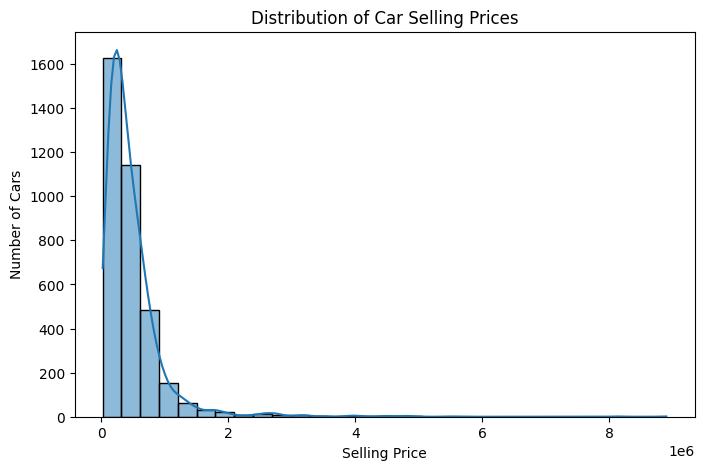

In [7]:
plt.figure(figsize=(8, 5))

sns.histplot(df['selling_price'], bins=30, kde=True)

plt.title("Distribution of Car Selling Prices")
plt.xlabel("Selling Price")
plt.ylabel("Number of Cars")

plt.show()

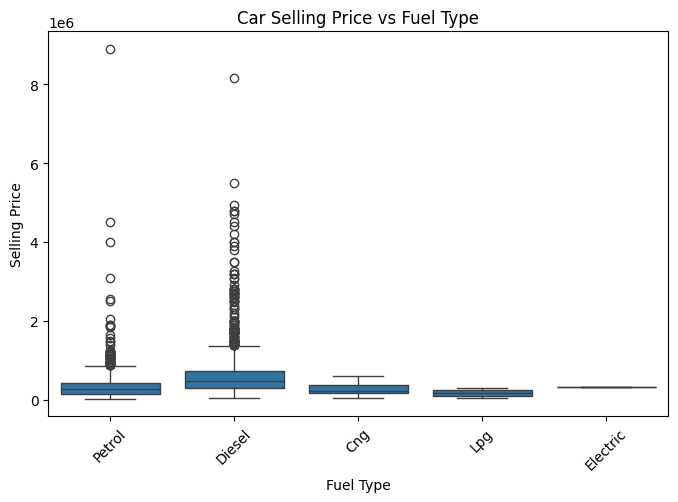

In [8]:
plt.figure(figsize=(8, 5))

sns.boxplot(x='fuel', y='selling_price', data=df)

plt.title("Car Selling Price vs Fuel Type")
plt.xlabel("Fuel Type")
plt.ylabel("Selling Price")

plt.xticks(rotation=45)
plt.show()

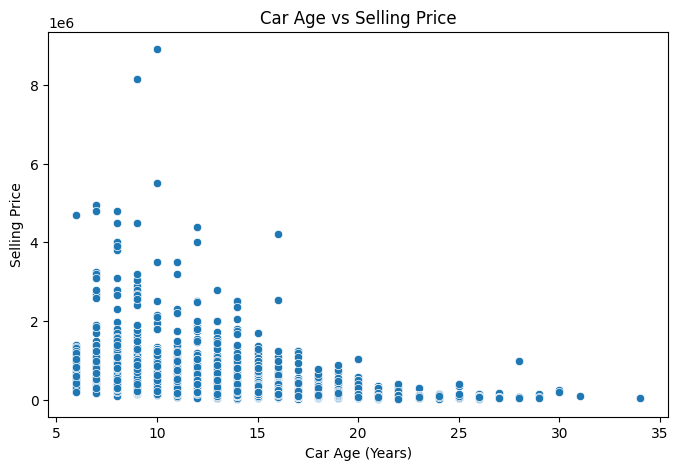

In [9]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    x='car_age',
    y='selling_price',
    data=df
)

plt.title("Car Age vs Selling Price")
plt.xlabel("Car Age (Years)")
plt.ylabel("Selling Price")

plt.show()

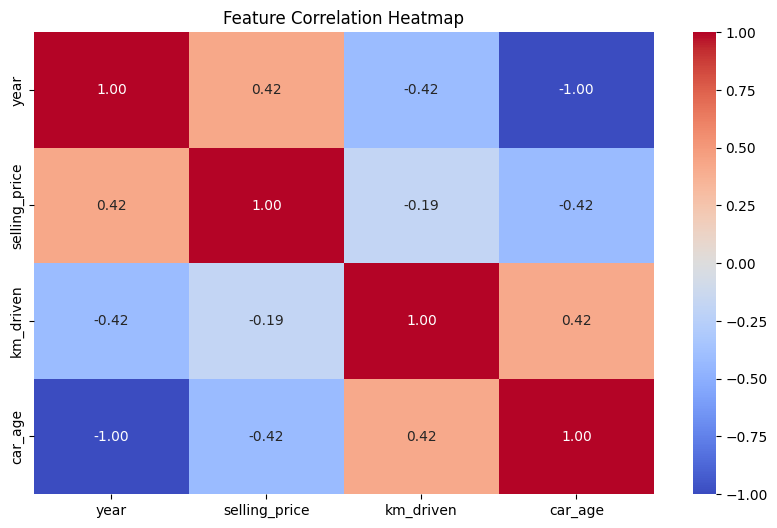

In [10]:
# Select numerical columns
numeric_df = df.select_dtypes(include=['number'])

# Create correlation matrix
correlation = numeric_df.corr()

# Plot heatmap
plt.figure(figsize=(10, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Feature Correlation Heatmap")
plt.show()

In [11]:
# Create a copy for machine learning
ml_df = df.copy()

# Remove car name because brand is already extracted
ml_df = ml_df.drop(columns=['name'])

# Convert categorical columns into numerical columns
ml_df = pd.get_dummies(
    ml_df,
    columns=['fuel', 'seller_type', 'transmission', 'owner', 'brand'],
    drop_first=True,
    dtype=int
)

# Display encoded data
print("Encoded Dataset:")
print(ml_df.head())

# Check dataset shape
print("\nNew Dataset Shape:", ml_df.shape)

# Check data types
print("\nData Types:")
print(ml_df.dtypes)

Encoded Dataset:
   year  selling_price  km_driven  car_age  fuel_Diesel  fuel_Electric  \
0  2007          60000      70000       19            0              0   
1  2007         135000      50000       19            0              0   
2  2012         600000     100000       14            1              0   
3  2017         250000      46000        9            0              0   
4  2014         450000     141000       12            1              0   

   fuel_Lpg  fuel_Petrol  seller_type_Individual  \
0         0            1                       1   
1         0            1                       1   
2         0            0                       1   
3         0            1                       1   
4         0            0                       1   

   seller_type_Trustmark Dealer  ...  brand_Mercedes-Benz  brand_Mitsubishi  \
0                             0  ...                    0                 0   
1                             0  ...                    0          

In [12]:
from sklearn.model_selection import train_test_split

# Separate input features and target variable
X = ml_df.drop('selling_price', axis=1)
y = ml_df['selling_price']

# Split dataset into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

# Display dataset sizes
print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Data: (2861, 42)
Testing Data: (716, 42)
Training Target: (2861,)
Testing Target: (716,)


In [13]:
from sklearn.linear_model import LinearRegression

# Create Linear Regression model
lr_model = LinearRegression()

# Train the model
lr_model.fit(X_train, y_train)

# Predict car prices
lr_predictions = lr_model.predict(X_test)

print("Linear Regression Model Trained Successfully!")

# Display first 10 predictions
print("\nActual Prices:")
print(y_test.head(10).values)

print("\nPredicted Prices:")
print(lr_predictions[:10])

Linear Regression Model Trained Successfully!

Actual Prices:
[ 270000  525000  990000 3800000  229999  325000  210000  500000  790000
  360000]

Predicted Prices:
[ 527597.75050626  470512.27211417  954225.66808569 2035903.76843295
  142904.5403322   376689.61468202  168008.34576924  530721.49389809
  801828.67276175  418051.82259752]


In [14]:
from sklearn.ensemble import RandomForestRegressor

# Create Random Forest model
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

# Train the model
rf_model.fit(X_train, y_train)

# Predict car prices
rf_predictions = rf_model.predict(X_test)

print("Random Forest Model Trained Successfully!")

# Display first 10 predictions
print("\nActual Prices:")
print(y_test.head(10).values)

print("\nPredicted Prices:")
print(rf_predictions[:10])

Random Forest Model Trained Successfully!

Actual Prices:
[ 270000  525000  990000 3800000  229999  325000  210000  500000  790000
  360000]

Predicted Prices:
[ 568614.04401154  461767.40916667 1463569.893      2552030.
  241075.          360948.08690476  182908.33333333  682261.96
  871519.05380952  467530.        ]


In [15]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
import numpy as np

# Evaluate Linear Regression
lr_mae = mean_absolute_error(y_test, lr_predictions)
lr_rmse = np.sqrt(mean_squared_error(y_test, lr_predictions))
lr_r2 = r2_score(y_test, lr_predictions)

# Evaluate Random Forest
rf_mae = mean_absolute_error(y_test, rf_predictions)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_predictions))
rf_r2 = r2_score(y_test, rf_predictions)

# Display comparison
results = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest'],
    'MAE': [lr_mae, rf_mae],
    'RMSE': [lr_rmse, rf_rmse],
    'R2 Score': [lr_r2, rf_r2]
})

print(results)

               Model            MAE           RMSE  R2 Score
0  Linear Regression  180194.987022  385606.086098  0.538415
1      Random Forest  159293.673640  365093.633557  0.586217


                   Feature  Importance
9      transmission_Manual    0.244025
1                km_driven    0.127027
2                  car_age    0.121760
0                     year    0.113241
3              fuel_Diesel    0.070997
14              brand_Audi    0.052723
6              fuel_Petrol    0.042618
28              brand_Land    0.040374
39            brand_Toyota    0.037311
7   seller_type_Individual    0.018456
15               brand_BMW    0.013794
32     brand_Mercedes-Benz    0.010424
31            brand_Maruti    0.010327
25            brand_Jaguar    0.010163
30          brand_Mahindra    0.009194


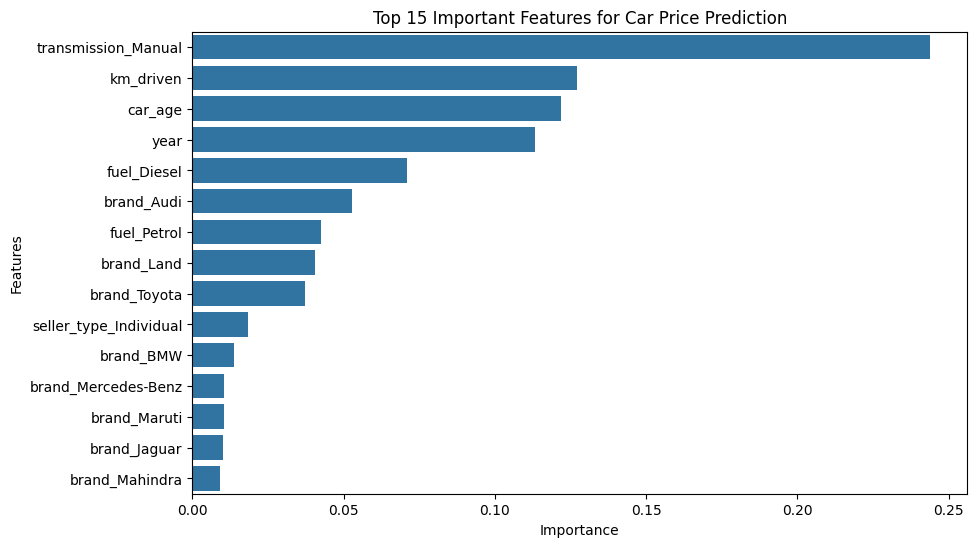

In [16]:
# Get feature importance from Random Forest
importance = rf_model.feature_importances_

# Create DataFrame
feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': importance
})

# Sort by importance
feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

# Display top 15 features
print(feature_importance.head(15))

# Plot feature importance
plt.figure(figsize=(10, 6))

sns.barplot(
    x='Importance',
    y='Feature',
    data=feature_importance.head(15)
)

plt.title("Top 15 Important Features for Car Price Prediction")
plt.xlabel("Importance")
plt.ylabel("Features")
plt.show()

In [17]:
sample_car = X_test.iloc[[0]]

predicted_price = rf_model.predict(sample_car)[0]
actual_price = y_test.iloc[0]

print("Predicted Car Price:", round(predicted_price, 2))
print("Actual Car Price:", round(actual_price, 2))

Predicted Car Price: 568614.04
Actual Car Price: 270000


# Conclusion

In this project, I developed a Car Price Prediction model using Machine Learning.

- Loaded and cleaned the CarDekho dataset.
- Performed Exploratory Data Analysis (EDA).
- Created new features such as car age and brand.
- Used one-hot encoding for categorical data.
- Trained Linear Regression and Random Forest models.
- Evaluated models using MAE, RMSE, and R2 Score.
- Compared both models using evaluation metrics.

**Result:** Random Forest performed better than Linear Regression, with an R2 score of approximately 0.586.

This project helped me understand data preprocessing, visualization, model training, and evaluation.